In [28]:
import os
# import xarray as xr
import socket
import subprocess
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
import scipy as sp
# import cupy as cp
# import cucim
# from cucim.skimage.morphology import ball as GPUball
# from scipy import ndimage
# import cupyx.scipy.ndimage as GPUndimage
# import cucim.skimage.morphology as cumorph
# import skimage
# from joblib import Parallel, delayed
import pickle
import tikzplotlib

#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
    
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('host '+host+' currently not supported')

charge_path = os.path.join(toppath, 'processing', 'charge_dict.p')
charge_dict = pickle.load(open(charge_path, 'rb'))

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

plotpath = '/mpc/homes/fische_r/paper/06-water-transport-fbbpm-coely/tikzplots'

In [2]:
def swelling_XTM(sample, charge_dict):
    t0 = charge_dict[sample]['t0']
    t_tomo = (charge_dict[sample]['t_utc_tomo'] - t0)/60 - 11.5
    meanth = charge_dict[sample]['TH']
    memvol = charge_dict[sample]['membrane volume']

    return t_tomo, meanth, memvol

In [3]:
samples = list(charge_dict.keys())

In [4]:
samples

['4', '5', '6', '3II', '5II', '4II', '8x', '3III', '7x', '1']

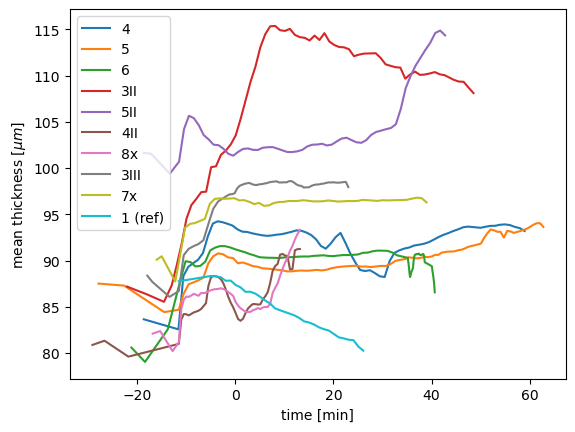

In [5]:
for sample in samples:
    t_tomo, meanth, memvol = swelling_XTM(sample, charge_dict)
    label = sample
    if label == '1':
        label = '1 (ref)'
    plt.plot(t_tomo, meanth*2.75, label=label)

plt.xlabel('time [min]')
plt.ylabel('mean thickness [$\mu m$]')
plt.legend()

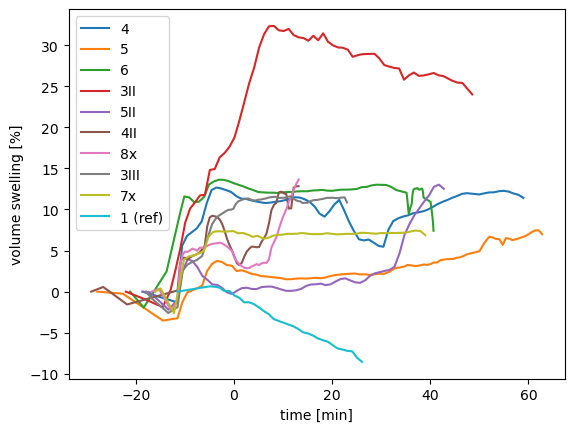

In [6]:
for sample in samples:
    t_tomo, meanth, memvol = swelling_XTM(sample, charge_dict)
    label = sample
    if label == '1':
        label = '1 (ref)'
    plt.plot(t_tomo, (memvol-memvol[0])/memvol[0]*100, label=label)

plt.xlabel('time [min]')
plt.ylabel('volume swelling [%]')
plt.legend()


In [12]:
symlist=  ['.', 'o', 'v','^','<','>', 's', '*','P','x']
len(symlist)

10

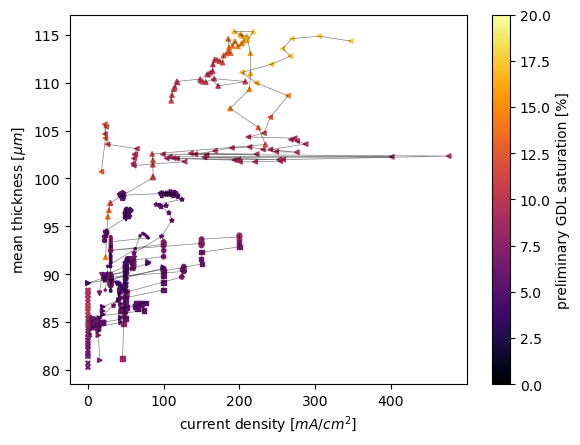

In [30]:
E0 = 0.795 #all carbonates
# E0 = 1.332 #all OH-
# E0 = 0
R = 5

fig, ax = plt.subplots()
# ax2 = ax.twinx()

Iall = np.array([])
Pall = np.array([])
THall = np.array([])
sall = np.array([])
Eall = np.array([])
Qall = np.array([])

vmin = 0#0
vmax= 20# 500
cmap = 'inferno'
norm = Normalize(vmin=vmin, vmax=vmax)
for i in range(len(samples)):
    sample = samples[i]
    # if sample == '5II': continue
    # if not sample == '7x': continue
    # try:
    t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
    sat = charge_dict[sample]['saturation']
    TH = charge_dict[sample]['TH']*2.75
    memvol = charge_dict[sample]['membrane volume']
    
    if not sample == '1':
        I = -charge_dict[sample]['I']
        time = charge_dict[sample]['time']
        Ifun = sp.interpolate.interp1d(time, I/0.1, fill_value=np.nan, bounds_error=False)

        Itomo = Ifun(t_tomo)
    
    if not sample == '1':
        ax.plot(Itomo, TH, 'k', linewidth = 0.5, alpha = 0.5)
        Iall = np.concatenate([Iall, Itomo])
        THall = np.concatenate([THall, TH])
        sall = np.concatenate([sall, sat])
        Eall = np.concatenate([Eall, Etomo])
        Qall = np.concatenate([Qall, Qtomo])
        
        ax.scatter(Itomo, TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap)
        
    else:
        ax.scatter(np.zeros(len(TH)), TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap)

    # except Exception as e:
    #     print(e)
    #     print(sample+' data not available')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),               #TODO: use revised water segmentation for GDL saturation
             ax=ax, label = 'preliminary GDL saturation [%]')# label="charge [$As/cm^2$]")
ax.set_xlabel('current density [$mA/cm^2$]')
ax.set_ylabel('mean thickness [$\mu m$]')
# tikzplotlib.save(os.path.join(plotpath, 'I_TH_abs.tex'))

11.408352138889954
7.000796884715537
7.409461170142053
24.004802037126378
12.50819814592944
12.835142444849131
13.649686602552555
10.850146520433578
6.87004319125009
-8.552943393776607


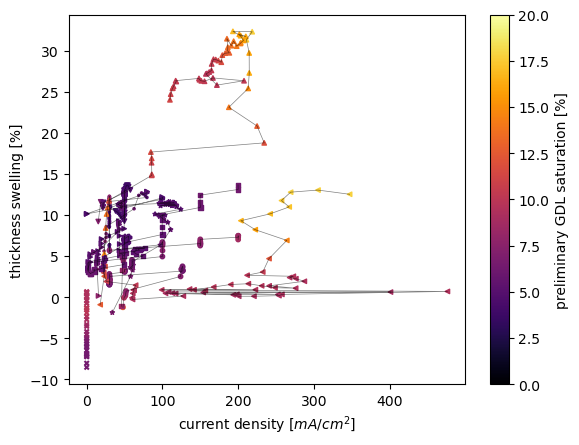

In [31]:
E0 = 0.795 #all carbonates
# E0 = 1.332 #all OH-
# E0 = 0
R = 5

fig, ax = plt.subplots()
# ax2 = ax.twinx()

Iall = np.array([])
Pall = np.array([])
THall = np.array([])
sall = np.array([])
Eall = np.array([])
Qall = np.array([])

vmin = 0#0
vmax= 20# 500
cmap = 'inferno'
norm = Normalize(vmin=vmin, vmax=vmax)
for i in range(len(samples)):
    sample = samples[i]
    # if sample == '5II': continue
    # if not sample == '7x': continue
    # try:
    t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
    sat = charge_dict[sample]['saturation']
    TH = charge_dict[sample]['TH']*2.75
    TH = (TH-TH[0])/TH[0]*100
    memvol = charge_dict[sample]['membrane volume']
    print(TH[-1])
    
    if not sample == '1':
        I = -charge_dict[sample]['I']
        time = charge_dict[sample]['time']
        Ifun = sp.interpolate.interp1d(time, I/0.1, fill_value=np.nan, bounds_error=False)

        Itomo = Ifun(t_tomo)
    
    if not sample == '1':
        ax.plot(Itomo, TH, 'k', linewidth = 0.5, alpha = 0.5)
        Iall = np.concatenate([Iall, Itomo])
        THall = np.concatenate([THall, TH])
        sall = np.concatenate([sall, sat])
        Eall = np.concatenate([Eall, Etomo])
        Qall = np.concatenate([Qall, Qtomo])
        
        ax.scatter(Itomo, TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap, label = sample)
        
    else:
        ax.scatter(np.zeros(len(TH)), TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap, label = sample)

    # except Exception as e:
    #     print(e)
    #     print(sample+' data not available')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),               #TODO: use revised water segmentation for GDL saturation
             ax=ax, label = 'preliminary GDL saturation [%]')# label="charge [$As/cm^2$]")
ax.set_xlabel('current density [$mA/cm^2$]')
ax.set_ylabel('thickness swelling [%]')
# ax.legend()
# tikzplotlib.save(os.path.join(plotpath, 'I_TH_rel.tex'))

In [21]:
TH

array([ 0.        ,  0.64792434,  0.59900938,  0.48966849,  0.06084362,
        0.08561548, -0.45857616, -0.74919041, -1.29978167, -1.29269834,
       -1.52329558, -1.91680274, -2.36652145, -2.74433185, -3.33901692,
       -3.56666827, -4.20259361, -4.52570939, -4.94584827, -5.0859957 ,
       -5.33024956, -5.6818987 , -5.90632276, -6.07835175, -6.48925066,
       -6.90924225, -7.04032117, -7.20478098, -7.26457155, -8.05241468,
       -8.55294339])

11.40835213888997
7.000796884715534
7.409461170142049
24.004802037126392
12.508198145929425
12.835142444849138
13.649686602552565
10.850146520433585
6.870043191250091
-8.552943393776623


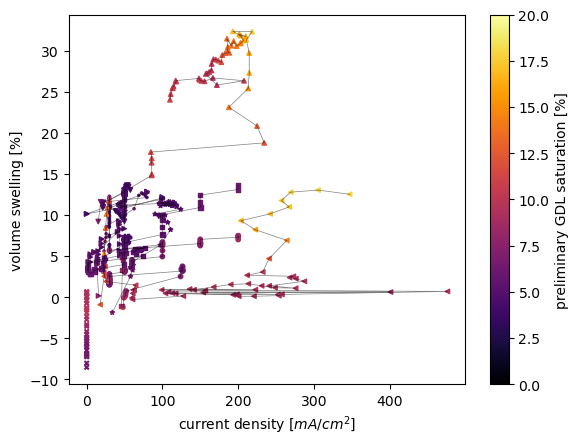

In [32]:
E0 = 0.795 #all carbonates
# E0 = 1.332 #all OH-
# E0 = 0
R = 5

fig, ax = plt.subplots()
# ax2 = ax.twinx()

Iall = np.array([])
Pall = np.array([])
THall = np.array([])
sall = np.array([])
Eall = np.array([])
Qall = np.array([])

vmin = 0#0
vmax= 20# 500
cmap = 'inferno'
norm = Normalize(vmin=vmin, vmax=vmax)
for i in range(len(samples)):
    sample = samples[i]
    # if sample == '5II': continue
    # if not sample == '7x': continue
    # try:
    t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
    sat = charge_dict[sample]['saturation']
    TH = charge_dict[sample]['TH']*2.75
    TH = (TH-TH[0])/TH[0]*100
    memvol = charge_dict[sample]['membrane volume']
    TH = (memvol-memvol[0])/memvol[0]*100
    print(TH[-1])
    
    if not sample == '1':
        I = -charge_dict[sample]['I']
        time = charge_dict[sample]['time']
        Ifun = sp.interpolate.interp1d(time, I/0.1, fill_value=np.nan, bounds_error=False)

        Itomo = Ifun(t_tomo)
    
    if not sample == '1':
        ax.plot(Itomo, TH, 'k', linewidth = 0.5, alpha = 0.5)
        Iall = np.concatenate([Iall, Itomo])
        THall = np.concatenate([THall, TH])
        sall = np.concatenate([sall, sat])
        Eall = np.concatenate([Eall, Etomo])
        Qall = np.concatenate([Qall, Qtomo])
        
        ax.scatter(Itomo, TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap, label = sample)
        
    else:
        ax.scatter(np.zeros(len(TH)), TH, marker=symlist[i], c = sat*100, vmin = vmin, vmax=vmax, s = 10, cmap = cmap, label = sample)

    # except Exception as e:
    #     print(e)
    #     print(sample+' data not available')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap),               #TODO: use revised water segmentation for GDL saturation
             ax=ax, label = 'preliminary GDL saturation [%]')# label="charge [$As/cm^2$]")
ax.set_xlabel('current density [$mA/cm^2$]')
ax.set_ylabel('volume swelling [%]')
# ax.legend()
tikzplotlib.save(os.path.join(plotpath, 'I_vol_rel.tex'))

In [22]:
sat

<xarray.DataArray 'segmented' (timestep: 31)>
array([0.09405902, 0.09325076, 0.09421934, 0.093165  , 0.0925782 ,
       0.09251956, 0.09256011, 0.09287155, 0.0973132 , 0.09808705,
       0.09980805, 0.09936947, 0.09493111, 0.09044555, 0.0876317 ,
       0.08389278, 0.07890547, 0.07850042, 0.07570308, 0.07215856,
       0.06795485, 0.06670026, 0.06482494, 0.06426485, 0.06433232,
       0.06417627, 0.06418859, 0.06441357, 0.06349603, 0.06359134,
       0.06405793])
Coordinates:
  * timestep  (timestep) int64 0 1 2 3 4 5 6 7 8 ... 22 23 24 25 26 27 28 29 30